In [ ]:
import pandas as pd
import numpy as np
pd.set_option('display.float_format', '{:,.2f}'.format)

# Read & Prepare Data

In [ ]:
dim_customer = pd.read_csv('dim_customer.csv')
dim_customer[]

dim_customer.head(3)

,customer_id,first_name,last_name,first_join_date,gender,birthdate,device_type
0,2870,Lala,Maryati,2019-07-21,F,1996-06-14,iOS
1,8193,Maimunah,Laksmiwati,2017-07-16,F,1993-08-16,Android
2,7279,Bakiman,Simanjuntak,2020-08-23,M,1989-01-23,iOS


In [ ]:
click_stream = pd.read_parquet('click_stream.parquet')

click_stream.head()

,session_id,customer_id,event_date,event_time,event_id,event_name,event_metadata,booking_id,sales_amount
0,07a9843b-c4ec-4bac-b063-05be3d920413,16555,2019-05-17,2019-05-17 10:23:09.906750+00:00,650c2658-5a77-4a8a-9415-758e4eb6bcd3,HOMEPAGE,None,None,NaN
1,07a9843b-c4ec-4bac-b063-05be3d920413,16555,2019-05-17,2019-05-17 16:20:22.906750+00:00,5e07ec2e-6eed-42b6-a818-9e88fae29e28,ADD_TO_CART,"{'product_id': 39306, 'quantity': 1, 'item_pri...",None,NaN
2,07a9843b-c4ec-4bac-b063-05be3d920413,16555,2019-05-17,2019-05-17 16:22:43.906750+00:00,b0eb25f1-3f3f-4a23-8cd8-6b85720f05a0,ITEM_DETAIL,None,None,NaN
3,07a9843b-c4ec-4bac-b063-05be3d920413,16555,2019-05-17,2019-05-17 22:25:12.906750+00:00,2dd8c127-6c56-45b3-a5fc-4b7a711e63fd,ADD_TO_CART,"{'product_id': 47413, 'quantity': 1, 'item_pri...",None,NaN
4,07a9843b-c4ec-4bac-b063-05be3d920413,16555,2019-05-18,2019-05-18 04:27:41.906750+00:00,c73b1ca3-811f-4ab4-aa1d-1e6c51d687cc,ADD_TO_CART,"{'product_id': 7383, 'quantity': 2, 'item_pric...",None,NaN


## Convert Date Type

In [ ]:
# dim_customer
dim_customer['first_join_date'] = pd.to_datetime(
    dim_customer['first_join_date'],
    errors='coerce'
)

dim_customer['birthdate'] = pd.to_datetime(
    dim_customer['birthdate'],
    errors='coerce'
)

# click_stream
click_stream['event_date'] = pd.to_datetime(
    click_stream['event_date'],
    errors='coerce'
)

click_stream['event_time'] = pd.to_datetime(
    click_stream['event_time'],
    errors='coerce'
)

click_stream['period_month'] = click_stream['event_date'].dt.to_period('M').dt.to_timestamp()

# Main KPI

In [ ]:
print('Date Range')
print(click_stream['event_date'].min())
print(click_stream['event_date'].max())

Date Range
2019-01-01 00:00:00
2019-12-31 00:00:00


## MAU (Monthly Active Users)

* MAU = melihat growth dari tahun ke tahun, atau dari awal tahun ke akhir tahun, melihat pola musiman seperti lebaran/natal

* DAU = melihat efek campaign/anomali tertentu (double date 6.6, 7.7, 11.11) atau pola weekly (weekend vs weekday)

In [ ]:
# Calculate Monthly Active Users (MAU)
mau = (
    click_stream
    .groupby('period_month')['customer_id']
    .nunique()
    .reset_index(name='monthly_active_users')
)

mau

,period_month,monthly_active_users
0,2019-01-01,564
1,2019-02-01,545
2,2019-03-01,587
3,2019-04-01,612
4,2019-05-01,626
5,2019-06-01,633
6,2019-07-01,746
7,2019-08-01,749
8,2019-09-01,780
9,2019-10-01,787


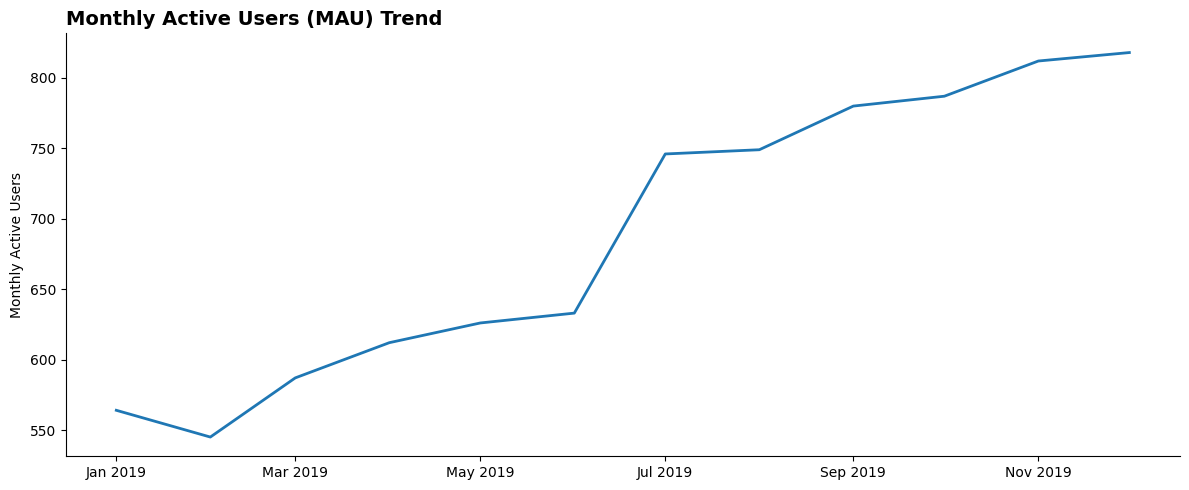

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Create line chart
plt.figure(figsize=(12, 5))

plt.plot(
    mau['period_month'],
    mau['monthly_active_users'],
    linewidth=2
)

# X-axis format: "Dec 2012"
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

# Minimalist style
plt.grid(False)
plt.xlabel('')
plt.ylabel('Monthly Active Users')
plt.title('Monthly Active Users (MAU) Trend', loc='left', fontsize=14, fontweight='bold')

# Remove unnecessary borders
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Rata-rata MAU di 2019

In [ ]:
print("Annual Active Users")
print( click_stream['customer_id'].nunique() )

print("\nAvg Monthly Active Users")
print( mau['monthly_active_users'].mean() )

Annual Active Users
1499

Avg Monthly Active Users
688.25


## DAU (Daily Active Users)

In [ ]:
# Filter click_stream data for Q4 (October - December)
q4_click_stream = click_stream[
    click_stream['event_time'].dt.month.isin([10, 11, 12])
].copy()

# Create date period
q4_click_stream['period_date'] = q4_click_stream['event_time'].dt.date

# Calculate DAU
dau_q4 = (
    q4_click_stream
    .groupby('period_date')['customer_id']
    .nunique()
    .reset_index(name='daily_active_users')
    .sort_values('period_date')
)

dau_q4

,period_date,daily_active_users
0,2019-10-01,136
1,2019-10-02,131
2,2019-10-03,138
3,2019-10-04,122
4,2019-10-05,140
...,...,...
87,2019-12-27,142
88,2019-12-28,149
89,2019-12-29,146
90,2019-12-30,148


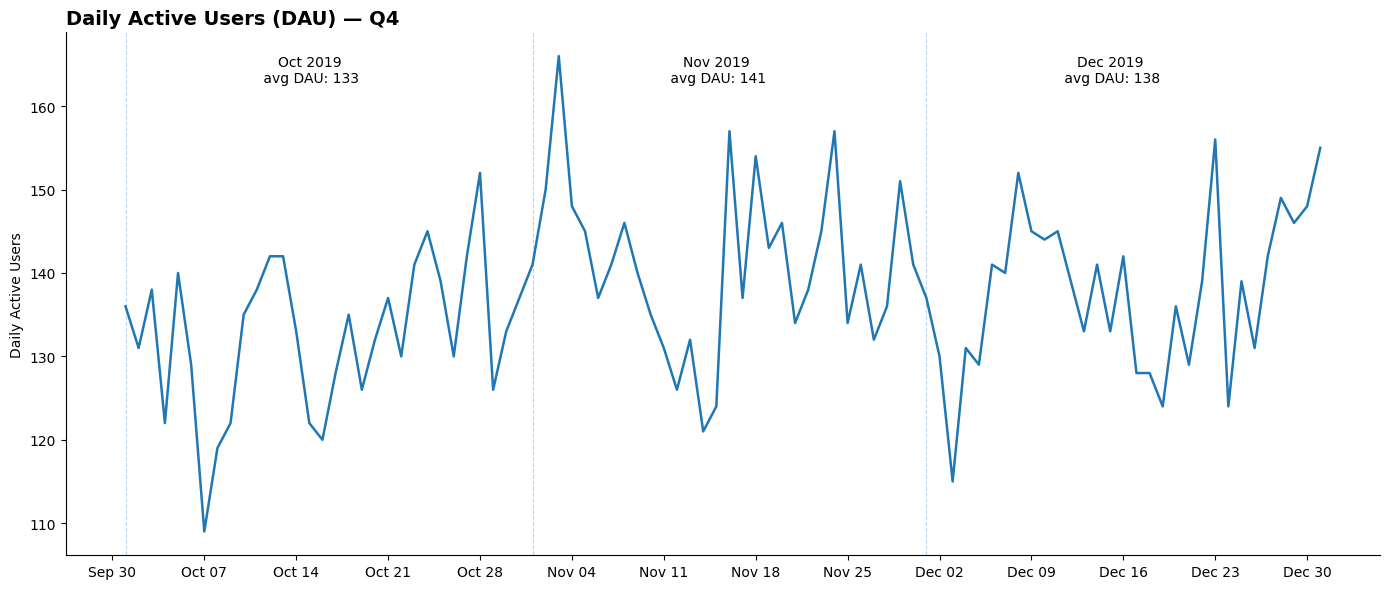

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Make sure period_date is datetime
dau_q4['period_date'] = pd.to_datetime(dau_q4['period_date'])

# Calculate monthly average DAU
monthly_avg_dau = (
    dau_q4
    .assign(period_month=dau_q4['period_date'].dt.to_period('M'))
    .groupby('period_month')['daily_active_users']
    .mean()
)

# Create the chart
fig, ax = plt.subplots(figsize=(14, 6))

# DAU line
ax.plot(
    dau_q4['period_date'],
    dau_q4['daily_active_users'],
    linewidth=1.8
)

# Add vertical lines at the start of each month
for month in monthly_avg_dau.index:
    month_start = month.to_timestamp()

    ax.axvline(
        month_start,
        linestyle='--',
        linewidth=0.8,
        alpha=0.3
    )

# Add monthly average DAU labels
for month, avg_dau in monthly_avg_dau.items():
    month_start = month.to_timestamp()

    # Position label on the 15th of each month
    mid_month = month_start + pd.Timedelta(days=14)

    ax.annotate(
        f'{month.strftime("%b %Y")}\n avg DAU: {avg_dau:.0f}',
        xy=(mid_month, 160),
        xytext=(0, 15),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=10
    )

# X-axis formatting
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

# Keep x-axis labels horizontal
plt.xticks(rotation=0)

# Minimalist style — no gridlines
ax.grid(False)

# Remove unnecessary borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Labels and title
ax.set_xlabel('')
ax.set_ylabel('Daily Active Users')
ax.set_title(
    'Daily Active Users (DAU) — Q4',
    loc='left',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## ARPU (Avg Revenue per User)

In [ ]:
# Summary metrics for click_stream

active_user = click_stream['customer_id'].nunique()

# Customers who made at least one purchase
unique_purchaser = (
    click_stream.loc[click_stream['booking_id'].notna(), 'customer_id']
    .nunique()
)

# Total revenue
total_revenue = click_stream['sales_amount'].sum()

# Number of unique orders
orders = click_stream['booking_id'].nunique()

# Conversion rate
conversion_rate = unique_purchaser / active_user

# ARPU = total revenue / active users
arpu = total_revenue / active_user

# AOV = total revenue / orders
aov = total_revenue / orders

# Order frequency = orders / unique purchasers
order_frequency = orders / unique_purchaser

# Put everything into a summary DataFrame
summary = pd.DataFrame({
    'active_user': [active_user],
    'unique_purchaser': [unique_purchaser],
    'conversion_rate': [conversion_rate],
    'total_revenue': [total_revenue],
    'orders': [orders],
    'arpu': [arpu],
    'aov': [aov],
    'order_frequency': [order_frequency]
})

summary

,active_user,unique_purchaser,conversion_rate,total_revenue,orders,arpu,aov,order_frequency
0,1499,1258,0.84,"3,027,733,700.00",5714,"2,019,835.69","529,879.89",4.54


* ARPU: Berapa rata-rata revenue yang dihasilkan oleh 1 active user
* AOV (Average Order Value): Berapa rata-rata spending dalam 1 kali belanja ➡️ mengukur daya beli
* Frequency: Dari orang yang sudah belanja, dia rata-rata bisa belanja berapa kali? ➡️ mengukur loyalitas

Kalau dari active user 1499 bisa mendapatkan ARPU 2 juta, kita bisa pakai untuk estimasi ketika punya active user 3000, maka kita punya total revenue yang bisa didapatkan = 3000 user x ARPU 2 juta = 6 miliar

**Exercise**

- Buat trend line ARPU per bulannya seperti apa
- Apakah makin naik juga seperti MAU, atau cenderung konstan, atau malah turun?

In [ ]:
# Group by month and calculate metrics
monthly_summary = (
    click_stream
    .groupby('period_month')
    .agg(
        active_user=('customer_id', 'nunique'),
        unique_purchaser=(
            'customer_id',
            lambda x: x[click_stream.loc[x.index, 'booking_id'].notna()].nunique()
        ),
        total_revenue=('sales_amount', 'sum'),
        orders=('booking_id', 'nunique')
    )
    .reset_index()
)

# Calculate derived metrics
monthly_summary['conversion_rate'] = (
    monthly_summary['unique_purchaser'] /
    monthly_summary['active_user']
)

monthly_summary['arpu'] = (
    monthly_summary['total_revenue'] /
    monthly_summary['active_user']
)

monthly_summary['aov'] = (
    monthly_summary['total_revenue'] /
    monthly_summary['orders']
)

monthly_summary['order_frequency'] = (
    monthly_summary['orders'] /
    monthly_summary['unique_purchaser']
)

# Columns to highlight
heatmap_cols = [
    'conversion_rate',
    'arpu',
    'aov',
    'active_user'
]

# Display monthly_summary with heatmap
(
    monthly_summary
    .style
    .background_gradient(
        subset=heatmap_cols,
        cmap='Blues'
    )
    .format({
        'conversion_rate': '{:.1%}',
        'total_revenue': '{:,.0f}',
        'arpu': '{:,.2f}',
        'aov': '{:,.2f}',
        'order_frequency': '{:.2f}',
        'active_user': '{:,.0f}',
        'unique_purchaser': '{:,.0f}',
        'orders': '{:,.0f}'
    })
)

,period_month,active_user,unique_purchaser,total_revenue,orders,conversion_rate,arpu,aov,order_frequency
0,2019-01-01 00:00:00,564,322,"224,073,046",409,57.1%,"397,292.63","547,855.86",1.27
1,2019-02-01 00:00:00,545,283,"170,924,832",357,51.9%,"313,623.54","478,781.04",1.26
2,2019-03-01 00:00:00,587,338,"209,782,660",430,57.6%,"357,381.02","487,866.65",1.27
3,2019-04-01 00:00:00,612,348,"224,920,991",436,56.9%,"367,517.96","515,873.83",1.25
4,2019-05-01 00:00:00,626,358,"291,778,091",475,57.2%,"466,099.19","614,269.67",1.33
5,2019-06-01 00:00:00,633,333,"230,377,345",425,52.6%,"363,945.25","542,064.34",1.28
6,2019-07-01 00:00:00,746,385,"230,756,200",480,51.6%,"309,324.66","480,742.08",1.25
7,2019-08-01 00:00:00,749,428,"300,389,253",520,57.1%,"401,053.74","577,671.64",1.21
8,2019-09-01 00:00:00,780,404,"265,019,178",508,51.8%,"339,768.18","521,691.30",1.26
9,2019-10-01 00:00:00,787,414,"279,653,438",523,52.6%,"355,341.09","534,710.21",1.26


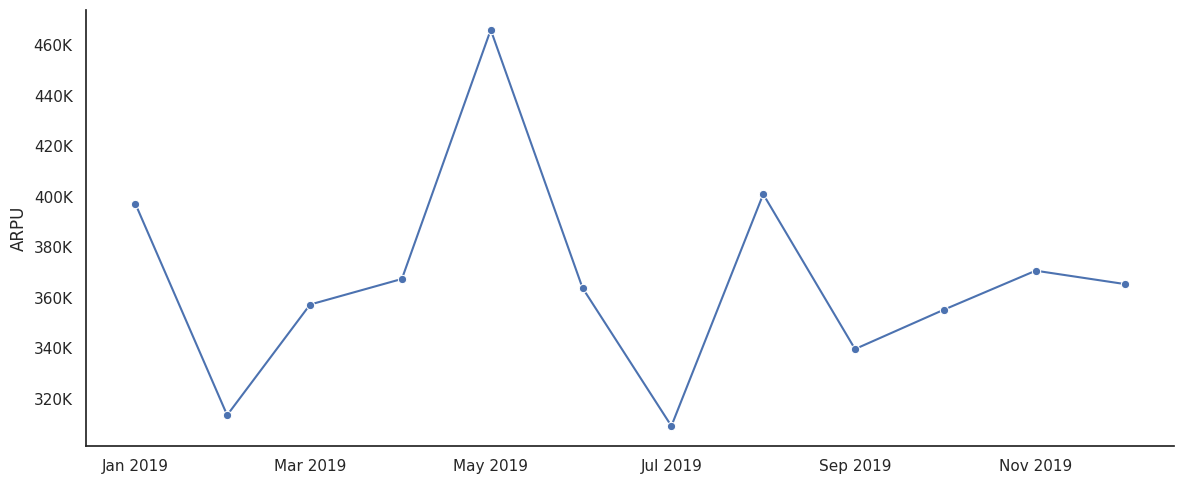

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="white")

fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=monthly_summary.reset_index(),
    x='period_month',
    y='arpu',
    marker='o',
    ax=ax
)

# Format date as "May 2019"
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x/1000:.0f}K')
)
# Minimalist formatting
ax.grid(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_xlabel('')
ax.set_ylabel('ARPU')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

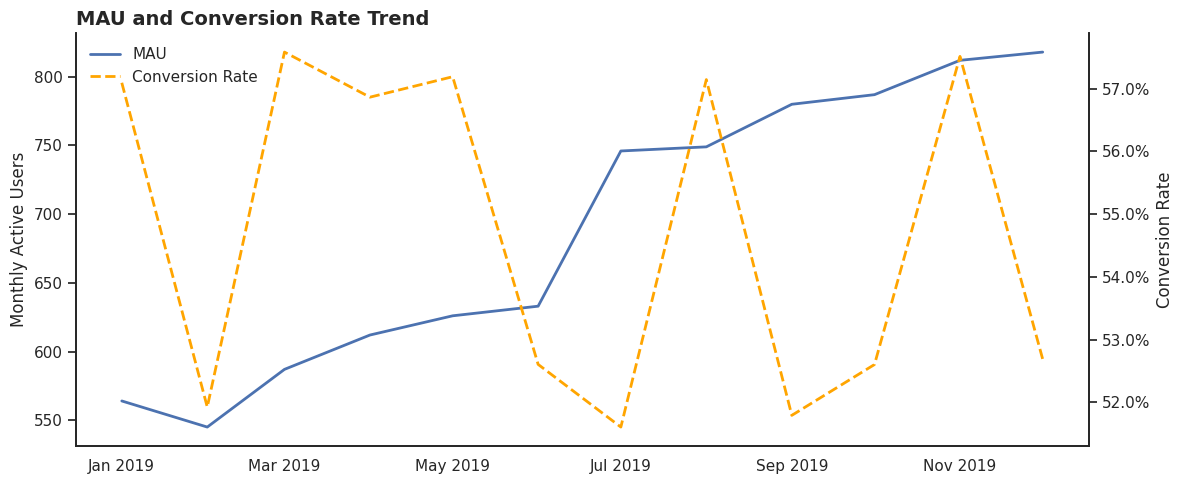

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax1 = plt.subplots(figsize=(12, 5))

# Left axis — MAU
ax1.plot(
    monthly_summary['period_month'],
    monthly_summary['active_user'],
    linewidth=2,
    label='MAU'
)

ax1.set_ylabel('Monthly Active Users')
ax1.set_xlabel('')
ax1.tick_params(axis='y')

# Right axis — Conversion Rate
ax2 = ax1.twinx()

ax2.plot(
    monthly_summary['period_month'],
    monthly_summary['conversion_rate'],
    linewidth=2,
    linestyle='--',
    label='Conversion Rate',
    color = 'orange'
)

ax2.set_ylabel('Conversion Rate')
ax2.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x:.1%}')
)

# X-axis format
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=0)

# Minimalist style — no gridlines
ax1.grid(False)
ax2.grid(False)

# Remove unnecessary borders
ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)

# Title
ax1.set_title(
    'MAU and Conversion Rate Trend',
    loc='left',
    fontsize=14,
    fontweight='bold'
)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc='upper left',
    frameon=False
)

plt.tight_layout()
plt.show()

## Retention Rate

Metrik singkat retention rate yang umum dipakai:
- Retention rate 30 days: Berapa customer yang kembali belanja dalam 1-30 hari pertama sejak tanggal registrasi

- Retention rate 90 days: Berapa customer yang kembali belanja dalam 1-90 hari pertama sejak tanggal registrasi

In [ ]:
# Join data customer dengan data click stream
click_stream = click_stream.merge(dim_customer, on = 'customer_id').copy()

- Memantau customer yang join Januari - September (karena harus ada periode 3 bulan ke depan/90 hari untuk dimonitor)
- Definisi retention bisa berbeda-beda tiap perusahaan, untuk case ini retention = active (tidak harus belanja)

In [ ]:
click_stream_selected = click_stream[ (click_stream['first_join_date'] >= '2019-01-01') &\
                                      (click_stream['first_join_date'] <= '2019-09-30') ].copy()

# Days since joining
click_stream_selected['days_since_join'] = (
    click_stream_selected['event_date'] - click_stream_selected['first_join_date']
).dt.days

click_stream_selected.head()

,session_id,customer_id,event_date,event_time,event_id,event_name,event_metadata,booking_id,sales_amount,period_month,first_name,last_name,first_join_date,gender,birthdate,device_type,days_since_join
5858,bd6aa2f4-a478-46b0-a4ff-991cd3c72176,45272,2019-07-14,2019-07-14 00:02:42.107498+00:00,760790a5-d2d0-4987-ba15-060b70ca82b8,HOMEPAGE,None,None,NaN,2019-07-01,Laswi,Mandala,2019-07-13,M,2004-06-12,iOS,1
5859,bd6aa2f4-a478-46b0-a4ff-991cd3c72176,45272,2019-07-14,2019-07-14 00:03:24.107498+00:00,7d0358bd-edaf-43de-a99d-da9a5e0f2729,ADD_TO_CART,"{'product_id': 33512, 'quantity': 1, 'item_pri...",None,NaN,2019-07-01,Laswi,Mandala,2019-07-13,M,2004-06-12,iOS,1
5860,bd6aa2f4-a478-46b0-a4ff-991cd3c72176,45272,2019-07-14,2019-07-14 00:10:59.786650+00:00,77089d23-ed1e-4775-b6f0-1c0601867216,BOOKING,{'payment_status': 'Success'},6f625619-53a6-43d5-80af-0820d591f0f6,"188,476.00",2019-07-01,Laswi,Mandala,2019-07-13,M,2004-06-12,iOS,1
5861,bd6aa2f4-a478-46b0-a4ff-991cd3c72176,45272,2019-07-14,2019-07-14 00:03:23.107498+00:00,767f671f-7cda-47da-8d38-ad530370b094,CLICK,None,None,NaN,2019-07-01,Laswi,Mandala,2019-07-13,M,2004-06-12,iOS,1
5862,bd6aa2f4-a478-46b0-a4ff-991cd3c72176,45272,2019-07-14,2019-07-14 00:04:05.107498+00:00,72c8b922-38ab-4a3b-b842-5140c9a3bf2a,ITEM_DETAIL,None,None,NaN,2019-07-01,Laswi,Mandala,2019-07-13,M,2004-06-12,iOS,1


### Retention Rate: 30-days & 90-days

In [ ]:
customer_retention = (
    click_stream_selected
    .groupby('customer_id')
    .agg(
        retained_30d=('days_since_join', lambda x: x.between(1, 30).any()),
        retained_90d=('days_since_join', lambda x: x.between(1, 90).any())
    )
    .reset_index()
)

summary = pd.DataFrame({
    'cohort_size': [len(customer_retention)],
    'retained_30d': [customer_retention['retained_30d'].sum()],
    'retained_90d': [customer_retention['retained_90d'].sum()]
}).assign(
    retention_30d=lambda x: x['retained_30d'] / x['cohort_size'] * 100,
    retention_90d=lambda x: x['retained_90d'] / x['cohort_size'] * 100,
    late_return_rate=lambda x: (
        (x['retained_90d'] - x['retained_30d']) /
        (x['cohort_size'] - x['retained_30d'])
    ) * 100
)

summary

,cohort_size,retained_30d,retained_90d,retention_30d,retention_90d,late_return_rate
0,470,308,354,65.53,75.32,28.40


Retention rate

- Ada 470 orang yang regist dari Jan-Sep
- Dari 470, ada 308 (65%) yang kembali aktif dalam 1-30 hari setelah registrasi
- Ada 354 (75%) yang kembali aktif dalam 1-90 hari pertama setelah registrasi
- Ada 28% orang yang baru kembali setelah 30 hari

### Breakdown by Cohort

In [ ]:
def retention_analysis(df, group_by=None):

    df = df.copy()

    # Days since joining
    df['days_since_join'] = (
        df['event_date'] - df['first_join_date']
    ).dt.days

    # Customer-level retention
    customer_retention = (
        df
        .groupby('customer_id', observed = False)
        .agg(
            retained_30d=(
                'days_since_join',
                lambda x: x.between(1, 30).any()
            ),
            retained_90d=(
                'days_since_join',
                lambda x: x.between(1, 90).any()
            )
        )
        .reset_index()
    )

    # Add grouping attribute if requested
    if group_by:
        customer_group = (
            df[['customer_id', group_by]]
            .drop_duplicates('customer_id')
        )

        customer_retention = customer_retention.merge(
            customer_group,
            on='customer_id',
            how='left'
        )

    # Cohort-level retention
    if group_by:

        result = (
            customer_retention
            .groupby(group_by, observed = False)
            .agg(
                cohort_size=('customer_id', 'nunique'),
                retained_30d=('retained_30d', 'sum'),
                retained_90d=('retained_90d', 'sum')
            )
            .reset_index()
        )

    else:

        result = pd.DataFrame({
            'cohort_size': [
                customer_retention['customer_id'].nunique()
            ],
            'retained_30d': [
                customer_retention['retained_30d'].sum()
            ],
            'retained_90d': [
                customer_retention['retained_90d'].sum()
            ]
        })

    # Retention rates
    result['retention_30d'] = (
        result['retained_30d'] /
        result['cohort_size'] *
        100
    )

    result['retention_90d'] = (
        result['retained_90d'] /
        result['cohort_size'] *
        100
    )

    # Late return rate
    result['late_return_rate'] = (
        (
            result['retained_90d'] -
            result['retained_30d']
        ) /
        (
            result['cohort_size'] -
            result['retained_30d']
        ) *
        100
    )

    return result

In [ ]:
# Tanpa group / cohort
retention_analysis(click_stream_selected)

,cohort_size,retained_30d,retained_90d,retention_30d,retention_90d,late_return_rate
0,470,308,354,65.53,75.32,28.40


In [ ]:
# Cohort/periode tanggal registrasi
click_stream_selected['period_regist'] = click_stream_selected['first_join_date'].dt.to_period('M').dt.to_timestamp()

# By Join Date
retention_analysis(click_stream_selected, group_by = 'period_regist')

,period_regist,cohort_size,retained_30d,retained_90d,retention_30d,retention_90d,late_return_rate
0,2019-01-01,31,21,23,67.74,74.19,20.00
1,2019-02-01,55,37,45,67.27,81.82,44.44
2,2019-03-01,57,41,44,71.93,77.19,18.75
3,2019-04-01,43,31,37,72.09,86.05,50.00
4,2019-05-01,46,32,36,69.57,78.26,28.57
5,2019-06-01,31,13,22,41.94,70.97,50.00
6,2019-07-01,81,55,60,67.90,74.07,19.23
7,2019-08-01,60,34,37,56.67,61.67,11.54
8,2019-09-01,66,44,50,66.67,75.76,27.27


In [ ]:
# By Gender
retention_analysis(click_stream_selected, group_by = 'gender')

,gender,cohort_size,retained_30d,retained_90d,retention_30d,retention_90d,late_return_rate
0,F,309,203,231,65.70,74.76,26.42
1,M,161,105,123,65.22,76.40,32.14


In [ ]:
# By Device Type
retention_analysis(click_stream_selected, group_by = 'device_type')

,device_type,cohort_size,retained_30d,retained_90d,retention_30d,retention_90d,late_return_rate
0,Android,365,237,276,64.93,75.62,30.47
1,iOS,105,71,78,67.62,74.29,20.59


# Feature Adoption

In [ ]:
click_stream.value_counts('event_name')

,count
event_name,
HOMEPAGE,22561
CLICK,21943
ADD_TO_CART,19210
SCROLL,14416
ITEM_DETAIL,11337
SEARCH,10016
BOOKING,5714
PROMO_PAGE,5564
ADD_PROMO,3704


### Adoption Rate

Berapa banyak yang pakai?

Adoption rate = total user yang menggunakan feature tersebut (ada event tersebut di session-nya) / total active user

In [ ]:
search_adoption = pd.DataFrame({
    'active_user': [click_stream['customer_id'].nunique()],
    'search_user': [
        click_stream.loc[
            click_stream['event_name'] == 'SEARCH',
            'customer_id'
        ].nunique()
    ]
}).assign(
    search_adoption_rate=lambda x: (
        x['search_user'] / x['active_user'] * 100
    )
)

search_adoption

,active_user,search_user,search_adoption_rate
0,1499,1083,72.25


In [ ]:
monthly_search = (
    click_stream
    .groupby('period_month')
    .agg(
        active_user=('customer_id', 'nunique'),
        search_user=(
            'customer_id',
            lambda x: x[
                click_stream.loc[x.index, 'event_name'] == 'SEARCH'
            ].nunique()
        )
    )
    .assign(
        search_adoption=lambda x: (
            x['search_user'] / x['active_user'] * 100
        )
    )
)

monthly_search

,active_user,search_user,search_adoption
period_month,,,
2019-01-01,564,256,45.39
2019-02-01,545,246,45.14
2019-03-01,587,274,46.68
2019-04-01,612,279,45.59
2019-05-01,626,269,42.97
2019-06-01,633,276,43.60
2019-07-01,746,357,47.86
2019-08-01,749,344,45.93
2019-09-01,780,331,42.44


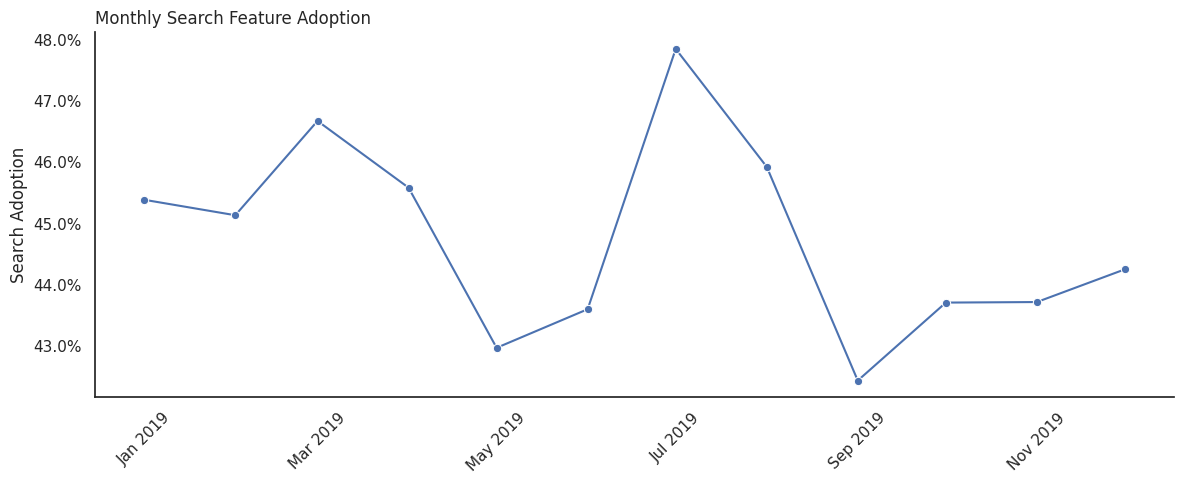

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick

sns.set_theme(style='white')

fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=monthly_search,
    x=monthly_search.index,
    y='search_adoption',
    marker='o',
    ax=ax
)

ax.yaxis.set_major_formatter(
    mtick.PercentFormatter()
)

ax.set_xlabel('')
ax.set_ylabel('Search Adoption')
ax.set_title('Monthly Search Feature Adoption', loc='left')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

ax.grid(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Adoption Uplift

Apakah orang-orang yang menggunakan feature pencarian menghasilkan conversion yang lebih tinggi? Atau cenderung punya retention lebih tinggi?

### Search

In [ ]:
# ============================================================
# 1. First Search for each customer
# ============================================================

first_search = (
    click_stream[
        click_stream['event_name'] == 'SEARCH'
    ]
    .groupby('customer_id')
    .agg(
        search_time=('event_time', 'min')
    )
    .reset_index()
)


# ============================================================
# 2. First Item Detail for each customer
#    Used as the index event for non-search users
# ============================================================

first_detail = (
    click_stream[
        click_stream['event_name'] == 'ITEM_DETAIL'
    ]
    .groupby('customer_id')
    .agg(
        detail_time=('event_time', 'min')
    )
    .reset_index()
)


# ============================================================
# 3. First Booking for each customer
# ============================================================

first_booking = (
    click_stream[
        click_stream['event_name'] == 'BOOKING'
    ]
    .groupby('customer_id')
    .agg(
        booking_time=('event_time', 'min')
    )
    .reset_index()
)


# ============================================================
# 4. Build user-level dataset
# ============================================================

user_search = (
    click_stream[['customer_id']]
    .drop_duplicates()
    .merge(
        first_search,
        on='customer_id',
        how='left'
    )
    .merge(
        first_detail,
        on='customer_id',
        how='left'
    )
    .merge(
        first_booking,
        on='customer_id',
        how='left'
    )
)


# ============================================================
# 5. Define Search vs Non-Search
# ============================================================

user_search['used_search'] = (
    user_search['search_time'].notna()
)


# ============================================================
# 6. Define index event
#
# Search users     → first SEARCH
# Non-search users → first ITEM_DETAIL
# ============================================================

user_search['index_time'] = (
    user_search['search_time']
    .combine_first(user_search['detail_time'])
)


# ============================================================
# 7. Conversion within 30 days
# ============================================================

user_search['converted'] = (
    (user_search['booking_time'] > user_search['index_time']  ) &
    (user_search['booking_time'] <= user_search['index_time'] + pd.Timedelta(days=30))
)


# ============================================================
# 8. Conversion summary
# ============================================================

search_conversion = (
    user_search
    .groupby('used_search')
    .agg(
        users=('customer_id', 'nunique'),
        converters=('converted', 'sum')
    )
    .assign(
        conversion_rate=lambda x:
            x['converters'] / x['users'] * 100
    )
    .reset_index()
)


# Rename segment
search_conversion['segment'] = (
    search_conversion['used_search']
    .map({
        True: 'Search',
        False: 'Non-Search'
    })
)


# Reorder columns
search_conversion = search_conversion[
    [
        'segment',
        'users',
        'converters',
        'conversion_rate'
    ]
]


search_conversion

,segment,users,converters,conversion_rate
0,Non-Search,416,78,18.75
1,Search,1083,468,43.21


In [ ]:
search_conversion_rate = (
    search_conversion.loc[
        search_conversion['segment'] == 'Search',
        'conversion_rate'
    ].iloc[0]
)

non_search_conversion_rate = (
    search_conversion.loc[
        search_conversion['segment'] == 'Non-Search',
        'conversion_rate'
    ].iloc[0]
)


uplift_pp = (
    search_conversion_rate -
    non_search_conversion_rate
)

uplift_pct = (
    search_conversion_rate /
    non_search_conversion_rate -
    1
) * 100

search_impact = pd.DataFrame({
    'search_users': [
        search_conversion.loc[
            search_conversion['segment'] == 'Search',
            'users'
        ].iloc[0]
    ],
    'non_search_users': [
        search_conversion.loc[
            search_conversion['segment'] == 'Non-Search',
            'users'
        ].iloc[0]
    ],
    'search_conversion': [search_conversion_rate],
    'non_search_conversion': [non_search_conversion_rate],
    'uplift_pp': [uplift_pp],
    'uplift_pct': [uplift_pct]
}).assign(
    search_conversion=lambda x:
        x['search_conversion'].map(lambda v: f'{v:.1f}%'),

    non_search_conversion=lambda x:
        x['non_search_conversion'].map(lambda v: f'{v:.1f}%'),

    uplift_pp=lambda x:
        x['uplift_pp'].map(lambda v: f'{v:+.1f} pp'),

    uplift_pct=lambda x:
        x['uplift_pct'].map(lambda v: f'{v:+.1f}%')
)


search_impact

,search_users,non_search_users,search_conversion,non_search_conversion,uplift_pp,uplift_pct
0,1083,416,43.2%,18.8%,+24.5 pp,+130.5%


- Dari 1499 active user, 1083 menggunakan search, 416 tidak
- Dari 1082 yang menggunakan search, 43% convert (belanja) dalam 30 hari setelah melakukan search
- Dari 416 yang tidak menggunakan search, 19% convert (belanja) dalam 30 hari setelah melihat informasi produk (item_detail) tanpa searching dulu
- Uplift = berapa % kenaikan conversion dari yang pakai search vs yang tidak pakai search

### Promo Page

In [ ]:
# ============================================================
# 1. First Search for each customer
# ============================================================

first_search = (
    click_stream[
        click_stream['event_name'] == 'PROMO_PAGE'
    ]
    .groupby('customer_id')
    .agg(
        search_time=('event_time', 'min')
    )
    .reset_index()
)


# ============================================================
# 2. First Item Detail for each customer
#    Used as the index event for non-search users
# ============================================================

first_detail = (
    click_stream[
        click_stream['event_name'] == 'ITEM_DETAIL'
    ]
    .groupby('customer_id')
    .agg(
        detail_time=('event_time', 'min')
    )
    .reset_index()
)


# ============================================================
# 3. First Booking for each customer
# ============================================================

first_booking = (
    click_stream[
        click_stream['event_name'] == 'BOOKING'
    ]
    .groupby('customer_id')
    .agg(
        booking_time=('event_time', 'min')
    )
    .reset_index()
)


# ============================================================
# 4. Build user-level dataset
# ============================================================

user_search = (
    click_stream[['customer_id']]
    .drop_duplicates()
    .merge(
        first_search,
        on='customer_id',
        how='left'
    )
    .merge(
        first_detail,
        on='customer_id',
        how='left'
    )
    .merge(
        first_booking,
        on='customer_id',
        how='left'
    )
)


# ============================================================
# 5. Define Search vs Non-Search
# ============================================================

user_search['used_search'] = (
    user_search['search_time'].notna()
)


# ============================================================
# 6. Define index event
#
# Search users     → first SEARCH
# Non-search users → first ITEM_DETAIL
# ============================================================

user_search['index_time'] = (
    user_search['search_time']
    .combine_first(user_search['detail_time'])
)


# ============================================================
# 7. Conversion within 30 days
# ============================================================


user_search['converted'] = (
    (user_search['booking_time'] > user_search['index_time']  ) &
    (user_search['booking_time'] <= user_search['index_time'] + pd.Timedelta(days=30))
)


# ============================================================
# 8. Conversion summary
# ============================================================

search_conversion = (
    user_search
    .groupby('used_search')
    .agg(
        users=('customer_id', 'nunique'),
        converters=('converted', 'sum')
    )
    .assign(
        conversion_rate=lambda x:
            x['converters'] / x['users'] * 100
    )
    .reset_index()
)


# Rename segment
search_conversion['segment'] = (
    search_conversion['used_search']
    .map({
        True: 'Promo Page',
        False: 'Non-Promo Page'
    })
)


# Reorder columns
search_conversion = search_conversion[
    [
        'segment',
        'users',
        'converters',
        'conversion_rate'
    ]
]


search_conversion

,segment,users,converters,conversion_rate
0,Non-Promo Page,537,123,22.91
1,Promo Page,962,390,40.54


In [ ]:
search_conversion_rate = (
    search_conversion.loc[
        search_conversion['segment'] == 'Promo Page',
        'conversion_rate'
    ].iloc[0]
)

non_search_conversion_rate = (
    search_conversion.loc[
        search_conversion['segment'] == 'Non-Promo Page',
        'conversion_rate'
    ].iloc[0]
)


uplift_pp = (
    search_conversion_rate -
    non_search_conversion_rate
)

uplift_pct = (
    search_conversion_rate /
    non_search_conversion_rate -
    1
) * 100

search_impact = pd.DataFrame({
    'promo_users': [
        search_conversion.loc[
            search_conversion['segment'] == 'Promo Page',
            'users'
        ].iloc[0]
    ],
    'non_promo_users': [
        search_conversion.loc[
            search_conversion['segment'] == 'Non-Promo Page',
            'users'
        ].iloc[0]
    ],
    'promo_conversion': [search_conversion_rate],
    'non_promo_conversion': [non_search_conversion_rate],
    'uplift_pp': [uplift_pp],
    'uplift_pct': [uplift_pct]
}).assign(
    promo_conversion=lambda x:
        x['promo_conversion'].map(lambda v: f'{v:.1f}%'),

    non_promo_conversion=lambda x:
        x['non_promo_conversion'].map(lambda v: f'{v:.1f}%'),

    uplift_pp=lambda x:
        x['uplift_pp'].map(lambda v: f'{v:+.1f} pp'),

    uplift_pct=lambda x:
        x['uplift_pct'].map(lambda v: f'{v:+.1f}%')
)


search_impact

,promo_users,non_promo_users,promo_conversion,non_promo_conversion,uplift_pp,uplift_pct
0,962,537,40.5%,22.9%,+17.6 pp,+77.0%
